In [1]:
import numpy as onp
import matplotlib.pyplot as plt
from jax import numpy as np
from vmc_core import *
# from vmc_core import RNG

In [2]:
# for nu, nd in [(1,1), (2,2), (3,3), (6,6)]:
#     print(f"N_up={nu}, N_down={nd} | orbitals={occupied_orbitals(nu)} | E0={exact_energy(nu,nd)}")
# assert [exact_energy(n,n) for n in (1,2,3,6)] == [2,6,10,28]

In [3]:
# # Same-spin swap: one minus sign, no change in |psi|².
# X_test = RNG.normal(size=(20,6,2))
# X_swapped = X_test.copy()
# X_swapped[:,[0,1],:] = X_test[:,[1,0],:]
# a_test = RNG.normal(size=len(S_K))   # nonzero Jastrow: it must be symmetric under the swap too
# l1 = logpsi(X_test, a_test, 3)
# l2 = logpsi(X_swapped, a_test, 3)
# onp.testing.assert_allclose(l2, l1, atol=1e-12)
# s1 = np.linalg.slogdet(build_slaters(X_test, 3)[0])[0]
# s2 = np.linalg.slogdet(build_slaters(X_swapped, 3)[0])[0]
# onp.testing.assert_array_equal(s2, -s1)
# print("Same-spin exchange: sign flips and |psi|² is unchanged.")

In [4]:
# sweep_step = 5   # Metropolis steps between recorded samples: set it to about the tau printed below
# n_samples = 5000 # recorded samples per chain
# runs = {}        # (nu,nd) -> dictionary of results returned by sample_mcmc
# autocorr = {}
# # for nu,nd in [(1,1),(2,2),(3,1)]:
# for nu,nd in [(4,4)]:
#     res = sample_mcmc(logpsi, n_particles=nu + nd, n_samples=n_samples, n_discard=400, step_size=1.1, n_up=nu, n_chains=200,
#                       sweep_step=sweep_step, measures=("energy", "V", "density", "acceptance"))
#     runs[(nu,nd)] = res
#     e, err, sigma = res["energy"]["mean"], res["energy"]["error"], res["energy"]["sigma"]
#     V = res["V"]
#     expected = exact_energy(nu,nd)
#     print(f'{nu}+{nd}: VMC E={e[-1]:.12f} ± {err[-1]:.2g} | exact={expected} | '
#           f'acceptance={res["acceptance"]:.3f} | std of E_L={sigma[-1]:.2g}')
#     assert onp.abs(e[-1]-expected)<1e-10

#     autocorr[(nu,nd)] = autocorrelation(V)
#     tau = autocorrelation_time(autocorr[(nu,nd)])
#     print(f'{nu}+{nd}: autocorrelation time tau = {tau:.1f} recorded samples '
#           f'(sweep_step={sweep_step}) -> effective samples per chain ~ {len(V)/tau:.0f}')

In [5]:
# # Running mean vs iteration
# # E_L is constant for an exact eigenstate, so its running mean sits on E from the start and does not test the sampler.
# # Virial theorem (harmonic trap): <V> = <T> = E/2, so 2<V> -> E only if the samples are really distributed as |psi|^2
# fig, ax = plt.subplots(figsize=(6.6,3.7))
# for k, ((nu,nd), res) in enumerate(runs.items()):
#     V = res["V"]
#     it = onp.arange(1, len(V) + 1)
#     # running mean of each chain separately; the chains are independent, so the spread between them
#     # gives an honest error bar even though samples inside one chain are correlated
#     run_chain = onp.cumsum(V, axis=0) / it[:, None]             # shape (n_samples, n_chains)
#     mean = run_chain.mean(axis=1)
#     err = run_chain.std(axis=1, ddof=1) / onp.sqrt(run_chain.shape[1])
#     ax.plot(it, mean, color=f'C{k}', label=f'{nu}+{nd}: running mean of $V$')
#     ax.fill_between(it, mean - err, mean + err, color=f'C{k}', alpha=0.25, lw=0)
#     ax.axhline(exact_energy(nu,nd)/2, color=f'C{k}', ls='--', lw=0.8)
# ax.set(xlabel='Iteration (recorded sample)', ylabel='Running mean', title='Convergence to the expec. val. of V (dashed)')
# ax.legend(frameon=False, fontsize=8)
# plt.show()

In [6]:
# # Radial density: VMC histogram (error bars from the spread of the chains) and exact n(r), both integrate to N
# # n_exact is the angular average for the 4+4 filling, so it is only drawn for that one
# fig, ax = plt.subplots(figsize=(6.6,3.7))
# for k, ((nu,nd), res) in enumerate(runs.items()):
#     r, density, err = density_from_hist(res["density"]["hist"], res["density"]["edges"], n_samples)
#     ax.errorbar(r, density, yerr=err, fmt='.', ms=5, lw=0.8, color=f'C{k}', label=f'{nu}+{nd}: VMC')
#     if (nu,nd) == (4,4):
#         ax.plot(r, n_exact(r), color='k', lw=1, zorder=3, label=f'{nu}+{nd}: exact')
# ax.set(xlabel='$r$', ylabel='$n(r)$ (particles per unit area)', title='Radial density')
# ax.legend(frameon=False, fontsize=8)
# plt.show()

In [7]:
# ===== Stage 2, task 1: two-body problem (needed for the comparisons below) =====
# V0 for each free-space binding energy E_B, then the exact E_2 and f0(r) in the trap at the same V0
from two_body import V0_for_EB, trapped_pair

E_Bs = (0.3, 1.0, 2.5)
two_body_exact = {}
for E_B in E_Bs:
    V0 = V0_for_EB(E_B)
    E2, r_rel, f0 = trapped_pair(V0)
    two_body_exact[E_B] = dict(V0=V0, E2=E2, r=r_rel, f0=f0)
    print(f'E_B = {E_B}: V0 = {V0:.4f}, exact E_2 = {E2:.6f}')

E_B = 0.3: V0 = 53.0531, exact E_2 = 0.978628


E_B = 1.0: V0 = 67.3770, exact E_2 = 0.140232


E_B = 2.5: V0 = 84.0281, exact E_2 = -1.431455


In [8]:
# ===== a_k = 0 and V0 = 0 must give back Stage 1 exactly =====
# E = E^(0) to machine precision and zero variance of E_L, for every filling and for the paired state too
for wf, nu, nd in [(logpsi, 1, 1), (logpsi, 2, 1), (logpsi, 2, 2), (logpsi_paired, 2, 2), (logpsi, 3, 3)]:
    res = sample_mcmc(wf, nu + nd, n_samples=200, n_discard=100, step_size=0.5, n_up=nu, n_chains=50,
                      measures=("energy",), params=onp.zeros(len(S_K)), V0=0.0, progress=False)
    E, sigma = res["energy"]["mean"][-1], res["energy"]["sigma"][-1]
    print(f'{wf.__name__:13s} {nu}+{nd}: E = {E:.12f} | E^(0) = {exact_energy(nu, nd)} | std of E_L = {sigma:.1e}')
    assert abs(E - exact_energy(nu, nd)) < 1e-10 and sigma < 1e-10

logpsi        1+1: E = 2.000000000000 | E^(0) = 2 | std of E_L = 3.2e-16


logpsi        2+1: E = 4.000000000000 | E^(0) = 4 | std of E_L = 7.1e-16


logpsi        2+2: E = 6.000000000000 | E^(0) = 6 | std of E_L = 1.6e-15


logpsi_paired 2+2: E = 6.000000000000 | E^(0) = 6 | std of E_L = 5.5e-15


logpsi        3+3: E = 10.000000000000 | E^(0) = 10 | std of E_L = 2.2e-15


In [9]:
# ===== N = 2: optimize the a_k (starting from a_k = 0), then one long run for the energy =====
# the energies of the optimization iterations are noisy (50 samples x 100 chains each), so the E_2 we quote comes from
# a separate run at the optimized a_k with 1000 chains
opt = {}   # (E_B, N, "single" or "paired") -> optimized a_k, energy at every iteration, final energy and its error
for E_B in E_Bs:
    V0 = two_body_exact[E_B]["V0"]
    a, hist = optimize_jastrow(logpsi, n_particles=2, n_up=1, V0=V0)
    res = sample_mcmc(logpsi, 2, n_samples=1000, n_discard=200, step_size=0.5, n_up=1, n_chains=1000,
                      measures=("energy",), params=a, V0=V0, progress=False)
    opt[(E_B, 2, "single")] = dict(a=a, hist=hist, E=res["energy"]["mean"][-1], err=res["energy"]["error"][-1])

print(' E_B |      E_2 VMC       | E_2 exact | VMC - exact')
for E_B in E_Bs:
    o, E2 = opt[(E_B, 2, "single")], two_body_exact[E_B]["E2"]
    print(f' {E_B:3} | {o["E"]:8.5f} +- {o["err"]:.5f} | {E2:9.5f} | {o["E"] - E2:+.5f}')

optimization:   0%|          | 0/30 [00:00<?, ?it/s]

optimization:   3%|▎         | 1/30 [00:03<01:49,  3.79s/it]

optimization:   7%|▋         | 2/30 [00:04<00:51,  1.82s/it]

optimization:  10%|█         | 3/30 [00:04<00:32,  1.19s/it]

optimization:  13%|█▎        | 4/30 [00:05<00:23,  1.12it/s]

optimization:  17%|█▋        | 5/30 [00:05<00:18,  1.38it/s]

... (81 outputs left out)

optimization:  97%|█████████▋| 29/30 [00:14<00:00,  2.12it/s]

optimization: 100%|██████████| 30/30 [00:14<00:00,  2.01it/s]

optimization: 100%|██████████| 30/30 [00:14<00:00,  2.05it/s]

 E_B |      E_2 VMC       | E_2 exact | VMC - exact
 0.3 |  0.97863 +- 0.00009 |   0.97863 | +0.00000
 1.0 |  0.14048 +- 0.00015 |   0.14023 | +0.00024
 2.5 | -1.43145 +- 0.00021 |  -1.43146 | +0.00001


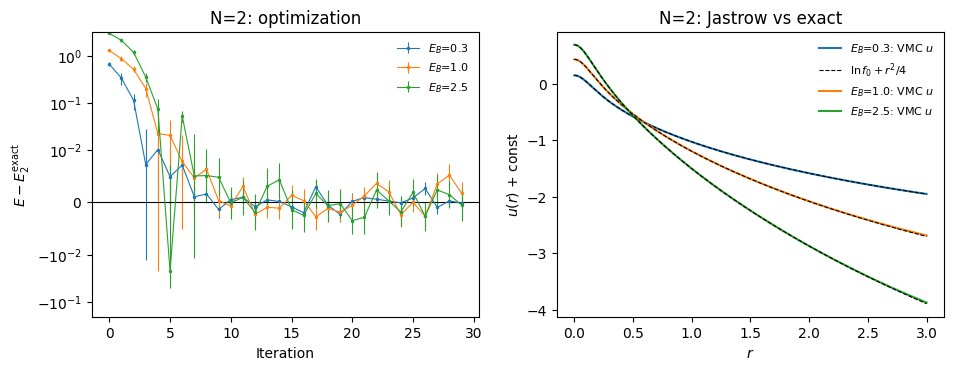

In [10]:
# Left: energy at every optimization iteration (each point is one short run), relative to the exact E_2.
# Right: optimized u(r) against ln f0 + r^2/4. For N=2 the exact state is e^{-R^2} f0(r), and the determinant part is
# phi_0(r_1) phi_0(r_2) = e^{-R^2} e^{-r^2/4}/pi, so the exact Jastrow is u = ln f0 + r^2/4 + const.
# The constant only changes the normalisation: we fix it by least squares, weighted with the pair distribution |f0|^2 r
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.7))
for k, E_B in enumerate(E_Bs):
    o, ex = opt[(E_B, 2, "single")], two_body_exact[E_B]
    it = onp.arange(len(o["hist"]))
    ax1.errorbar(it, o["hist"][:, 0] - ex["E2"], yerr=o["hist"][:, 1], fmt='.-', ms=3, lw=0.8, color=f'C{k}', label=f'$E_B$={E_B}')

    m = ex["r"] < 3
    r, f0 = ex["r"][m], ex["f0"][m]
    target = onp.log(f0) + r**2/4
    u = onp.exp(-r[:, None]**2 / (2*S_K**2)) @ o["a"]
    w = f0**2 * r
    c = onp.sum(w * (target - u)) / onp.sum(w)
    ax2.plot(r, u + c, color=f'C{k}', label=f'$E_B$={E_B}: VMC $u$')
    ax2.plot(r, target, 'k--', lw=0.8, label=r'$\ln f_0 + r^2/4$' if k == 0 else None)
ax1.axhline(0, color='k', lw=0.8)
ax1.set_yscale('symlog', linthresh=1e-2)
ax1.set(xlabel='Iteration', ylabel=r'$E - E_2^{\rm exact}$', title='N=2: optimization')
ax2.set(xlabel='$r$', ylabel='$u(r)$ + const', title='N=2: Jastrow vs exact')
ax1.legend(frameon=False, fontsize=8)
ax2.legend(frameon=False, fontsize=8)
plt.show()

In [11]:
# ===== N = 4 (2+2): single determinant vs paired state =====
# single: D_up[phi_0,phi_x] D_down[phi_0,phi_x];  paired: sum_{p=x,y} D_up[phi_0,phi_p] D_down[phi_0,phi_p]
# each one gets its own optimized a_k, starting from the N=2 ones at the same coupling, and the same final run
step_N4 = 0.3   # all particles move at once: 0.3 gives ~40% acceptance for N=4 (0.5 only ~20%)
for E_B in E_Bs:
    V0 = two_body_exact[E_B]["V0"]
    for name, wf in (("single", logpsi), ("paired", logpsi_paired)):
        a, hist = optimize_jastrow(wf, n_particles=4, n_up=2, V0=V0, params=opt[(E_B, 2, "single")]["a"], step_size=step_N4)
        res = sample_mcmc(wf, 4, n_samples=1000, n_discard=200, step_size=step_N4, n_up=2, n_chains=1000,
                          measures=("energy", "acceptance"), params=a, V0=V0, progress=False)
        opt[(E_B, 4, name)] = dict(a=a, hist=hist, E=res["energy"]["mean"][-1], err=res["energy"]["error"][-1],
                                   acceptance=res["acceptance"])

print(f' E_B | single determinant | paired state      | paired - single   (E^(0) = {exact_energy(2, 2)})')
for E_B in E_Bs:
    s, p = opt[(E_B, 4, "single")], opt[(E_B, 4, "paired")]
    print(f' {E_B:3} | {s["E"]:.4f} +- {s["err"]:.4f}  | {p["E"]:.4f} +- {p["err"]:.4f} | '
          f'{p["E"] - s["E"]:+.4f} +- {onp.hypot(s["err"], p["err"]):.4f}')

optimization:   0%|          | 0/30 [00:00<?, ?it/s]

optimization:   3%|▎         | 1/30 [00:04<02:15,  4.66s/it]

optimization:   7%|▋         | 2/30 [00:05<01:01,  2.21s/it]

optimization:  10%|█         | 3/30 [00:05<00:38,  1.42s/it]

optimization:  13%|█▎        | 4/30 [00:06<00:27,  1.04s/it]

optimization:  17%|█▋        | 5/30 [00:06<00:21,  1.18it/s]

... (177 outputs left out)

optimization:  97%|█████████▋| 29/30 [00:16<00:00,  1.68it/s]

optimization: 100%|██████████| 30/30 [00:17<00:00,  1.62it/s]

optimization: 100%|██████████| 30/30 [00:17<00:00,  1.72it/s]

 E_B | single determinant | paired state      | paired - single   (E^(0) = 6)
 0.3 | 3.6921 +- 0.0052  | 3.4270 +- 0.0043 | -0.2651 +- 0.0068
 1.0 | 2.1562 +- 0.0092  | 1.6840 +- 0.0080 | -0.4722 +- 0.0122
 2.5 | -0.5144 +- 0.0178  | -1.2753 +- 0.0140 | -0.7609 +- 0.0227


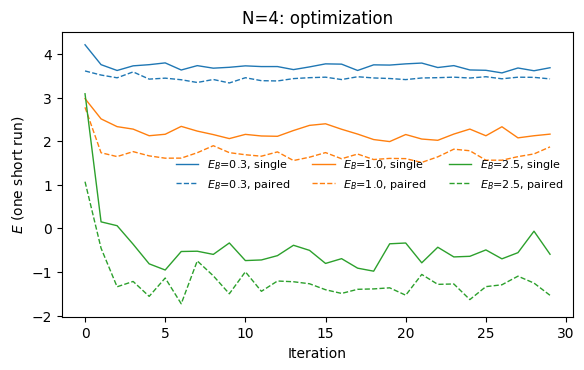

In [12]:
# N=4 optimization histories: check that 30 iterations are enough (the curves must be flat at the end)
fig, ax = plt.subplots(figsize=(6.6, 3.7))
for k, E_B in enumerate(E_Bs):
    for name, ls in (("single", '-'), ("paired", '--')):
        h = opt[(E_B, 4, name)]["hist"]
        ax.plot(h[:, 0], ls, color=f'C{k}', lw=1, label=f'$E_B$={E_B}, {name}')
ax.set(xlabel='Iteration', ylabel='$E$ (one short run)', title='N=4: optimization')
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.show()